# 01 · Your first trading strategy: moving-average crossover

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kolyamkl/qm-fintech-quant-workshop/blob/main/notebooks/01_workshop_ma_crossover.ipynb)

*QM FinTech Society quant workshop · Led by **Adnan Salehin** (Lead SWE & VP, JPMorgan)*

**What you'll do (~60 min):**
1. Load ten years of real price data
2. Turn prices into returns
3. Build a trading signal from two moving averages
4. Backtest it and compare with simply buying and holding
5. See three classic mistakes that make backtests lie
6. Change it and make it yours

Cells marked **✏️ Try it** are for you to edit and re-run.

> **Running in Google Colab?** If Colab warns that this notebook wasn't written by Google, click **Run anyway**. Then use **File → Save a copy in Drive** so your changes are kept.

In [1]:
# ▶ Setup — run this cell first.
# In Google Colab it downloads the workshop repo; on your laptop it just finds the code.
import os, subprocess, sys

REPO = "qm-fintech-quant-workshop"
if "google.colab" in sys.modules and os.path.basename(os.getcwd()) != REPO:
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", f"https://github.com/kolyamkl/{REPO}.git"], check=True)
    os.chdir(REPO)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # the code lives one folder up from notebooks/
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# Re-load your edited .py files automatically (handy when you change strategies/template.py)
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
pd.set_option("display.precision", 4)

## 1. Load the data

All prices live in one file, `data/prices.csv`: one row per ticker per day. Let's open it with plain pandas first so nothing is hidden.

In [2]:
df = pd.read_csv("data/prices.csv", parse_dates=["Date"])
df.head()

,Date,Ticker,Open,High,Low,Close,Volume
0,2016-01-04,AAPL,23.0726,23.6932,22.9354,23.6887,270597600
1,2016-01-05,AAPL,23.7786,23.8011,23.0276,23.0951,223164000
2,2016-01-06,AAPL,22.6116,23.0186,22.4565,22.6431,273829600
3,2016-01-07,AAPL,22.1889,22.5149,21.6829,21.6874,324377600
4,2016-01-08,AAPL,22.1596,22.2856,21.7572,21.8021,283192000


In [3]:
print(df.shape)
print(sorted(df["Ticker"].unique()))

(64992, 7)
['AAPL', 'AMZN', 'DIA', 'GLD', 'GOOGL', 'IEF', 'IWM', 'JNJ', 'JPM', 'MSFT', 'PG', 'QQQ', 'SPY', 'TLT', 'XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY', 'XOM']


To work with one ticker, filter its rows and use the date as the index:

In [4]:
spy = df[df["Ticker"] == "SPY"].set_index("Date")
spy.tail()

,Ticker,Open,High,Low,Close,Volume
Date,,,,,,
2026-10-05,SPY,769.69,776.61,769.63,774.83,44840200
2026-10-06,SPY,778.15,781.62,777.96,779.09,36054300
2026-10-07,SPY,775.77,779.10,773.61,777.22,30989200
2026-10-08,SPY,774.86,777.09,770.44,773.93,40431100
2026-10-09,SPY,776.24,779.42,775.14,778.57,22596500


That's common enough that the repo has a one-line helper doing exactly the same:

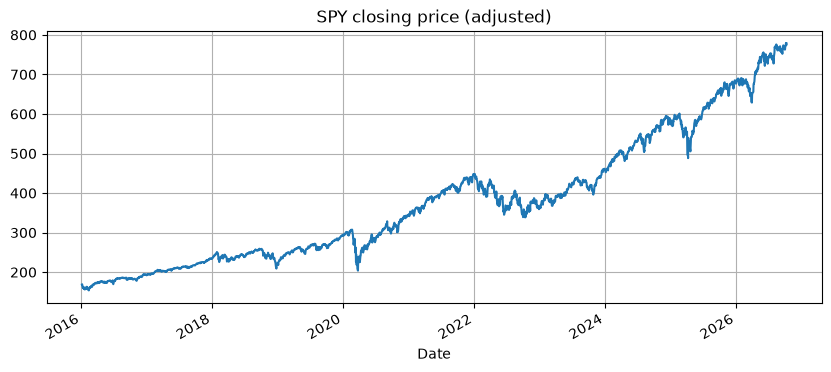

In [5]:
from backtester import load_prices, run_backtest

spy = load_prices("SPY")
spy["Close"].plot(figsize=(10, 4), title="SPY closing price (adjusted)", grid=True)
plt.show()

**✏️ Try it:** change `"SPY"` above to `"AAPL"`, `"XLE"` or `"GLD"` and re-run. Then set it back to SPY.

## 2. From prices to returns

Traders care about **returns** — percentage changes — not price levels: +1% means the same thing for a $10 stock and a $500 stock.

In [6]:
returns = spy["Close"].pct_change()
returns.describe()

count    2707.0000
mean        0.0006
std         0.0111
min        -0.1094
25%        -0.0036
50%         0.0007
75%         0.0059
max         0.1050
Name: Close, dtype: float64

In [7]:
print(f"Worst day: {returns.idxmin():%Y-%m-%d}  {returns.min():.1%}")
print(f"Best day:  {returns.idxmax():%Y-%m-%d}  {returns.max():.1%}")

Worst day: 2020-03-16  -10.9%
Best day:  2025-04-09  10.5%


Compounding daily returns gives the growth of $1 invested at the start:

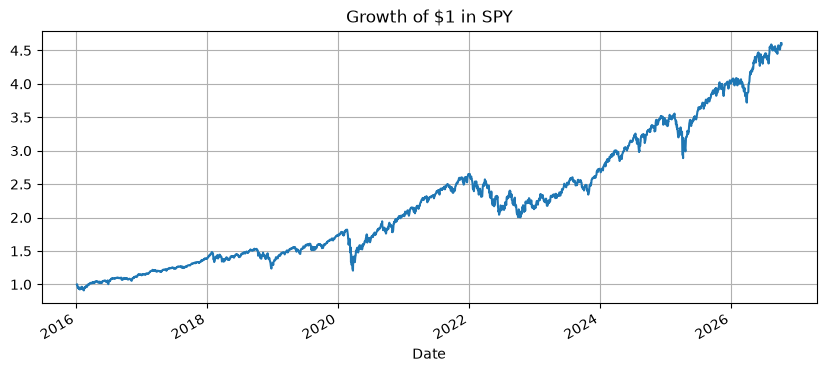

In [8]:
growth = (1 + returns.fillna(0)).cumprod()
growth.plot(figsize=(10, 4), title="Growth of $1 in SPY", grid=True)
plt.show()

## 3. A signal: the moving-average crossover

A **moving average** is the average of the last *N* closing prices. A short one (50 days) reacts quickly; a long one (200 days) shows the slow trend.

**The rule:** hold SPY while the 50-day average is above the 200-day average (an uptrend); otherwise sit in cash.

A 200-day average needs 200 days of prices before it exists, so the strategy sits in cash for that first stretch. This is called the **warm-up**.

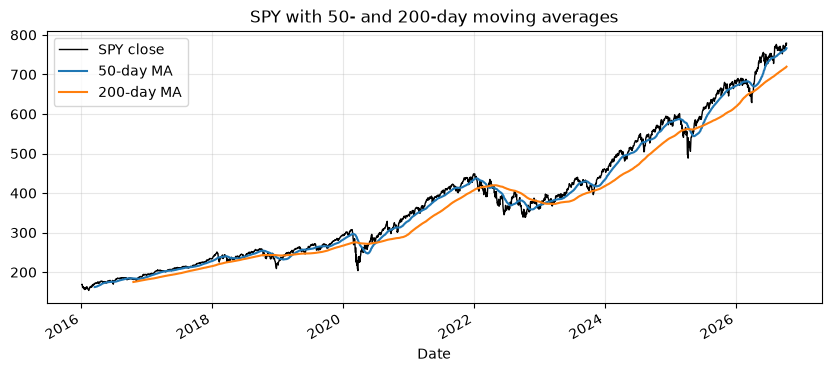

In [9]:
fast_ma = spy["Close"].rolling(50).mean()
slow_ma = spy["Close"].rolling(200).mean()

fig, ax = plt.subplots(figsize=(10, 4))
spy["Close"].plot(ax=ax, label="SPY close", color="black", linewidth=1)
fast_ma.plot(ax=ax, label="50-day MA")
slow_ma.plot(ax=ax, label="200-day MA")
ax.set_title("SPY with 50- and 200-day moving averages")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

The signal is one comparison. `1` = hold SPY, `0` = cash:

In [10]:
position = (fast_ma > slow_ma).astype(int)
position.value_counts()

Close
1    2107
0     601
Name: count, dtype: int64

That logic is exactly what `strategies/ma_crossover.py` contains — open the file and see. Using it gives the same answer:

In [11]:
from strategies import ma_crossover

positions = ma_crossover(spy, fast=50, slow=200)
bool((positions == position).all())

True

## 4. Backtest it

`run_backtest` turns positions into a portfolio value, starting from $10,000 and paying 5 bps (0.05%) every time the position changes.

One crucial detail: a signal computed from **today's** close can only earn **tomorrow's** return. The engine shifts positions by one day for you — open `backtester/engine.py` and find the comment *"THE MOST IMPORTANT LINE IN THIS REPO"*.

In [12]:
result = run_backtest(spy, positions, cost_bps=5)
result.summary()

,Strategy,Buy & hold
Total return,191.8%,360.6%
Annual return (CAGR),10.5%,15.3%
Annual volatility,14.7%,17.7%
Sharpe ratio,0.75,0.89
Max drawdown,-33.7%,-33.7%
Number of trades,5,—
Win rate,80.0%,—


**Read the table:** did the strategy beat buy-and-hold on total return? On Sharpe ratio? On max drawdown? Trend following is often described as *"earn a bit less, but lose less in crashes"*. Compare the two max drawdowns: if they are similar, that's a lesson too. A moving average reacts slowly, so in a very fast crash the price can fall a long way before the averages cross. Whether a strategy is "better" depends on what you care about.

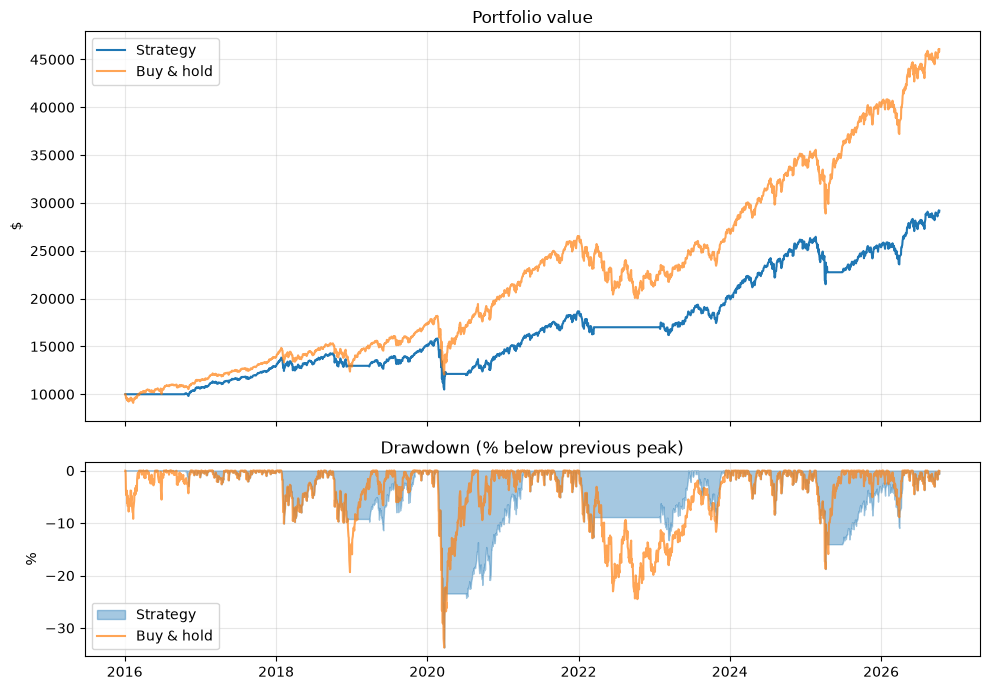

In [13]:
result.plot()

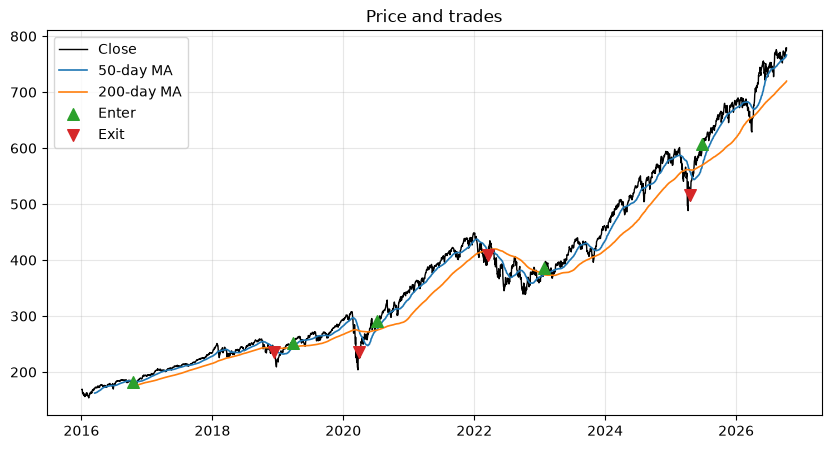

In [14]:
from backtester.plotting import plot_signals

plot_signals(spy, result, overlays={"50-day MA": fast_ma, "200-day MA": slow_ma})

In [15]:
result.trades

,entry_date,exit_date,direction,entry_price,exit_price,return,open
0,2016-10-17,2018-12-12,long,181.3716,235.5116,0.2985,False
1,2019-03-26,2020-03-31,long,251.9662,235.7402,-0.0644,False
2,2020-07-06,2022-03-16,long,291.2526,408.8679,0.4038,False
3,2023-01-26,2025-04-16,long,386.0568,517.0829,0.3394,False
4,2025-06-27,2026-10-09,long,606.6648,778.5700,0.2834,True


**✏️ Try it:** change `fast` and `slow` in the `ma_crossover(...)` cell (e.g. 20 and 100), then re-run the cells below it. What changes — the number of trades? the drawdown?

## 5. Three ways a backtest can lie

### 5a. Look-ahead bias

Here's a silly strategy: *"hold SPY on days it goes up"*. Impossible in real life — you don't know today's move until the day is over. Watch what happens if we forget the one-day shift:

In [16]:
close = spy["Close"]
daily = close.pct_change()
peek = (daily > 0).astype(int)  # 1 on days SPY rose — only knowable AFTER the close

cheating = (peek * daily).fillna(0)            # ❌ uses today's signal on today's return
honest = (peek.shift(1) * daily).fillna(0)     # ✅ today's signal, tomorrow's return

print(f"Cheating total return: {(1 + cheating).prod() - 1:,.0%}")
print(f"Honest total return:   {(1 + honest).prod() - 1:,.0%}")

Cheating total return: 3,953,212%
Honest total return:   57%


The "cheating" number is absurd because the strategy secretly knew the future. Real look-ahead bugs are subtler — but any backtest that looks too good to be true deserves this suspicion first.

### 5b. Transaction costs

Every trade costs money (fees, plus the gap between buy and sell prices). A strategy that trades rarely barely notices; one that trades often can be eaten alive. Compare the slow 50/200 crossover with a fast 5/20 one:

In [17]:
rows = []
for fast_n, slow_n in [(50, 200), (5, 20)]:
    pos = ma_crossover(spy, fast=fast_n, slow=slow_n)
    for cost in [0, 5, 20, 50]:
        r = run_backtest(spy, pos, cost_bps=cost)
        rows.append({"MA": f"{fast_n}/{slow_n}", "cost (bps)": cost, "total return": r.metrics["Total return"]})

pd.DataFrame(rows).pivot(index="cost (bps)", columns="MA", values="total return").style.format("{:.1%}")

MA,5/20,50/200
cost (bps),,
0,237.5%,193.2%
5,214.6%,191.8%
20,154.6%,187.9%
50,66.6%,180.2%


In [18]:
for fast_n, slow_n in [(50, 200), (5, 20)]:
    n = run_backtest(spy, ma_crossover(spy, fast=fast_n, slow=slow_n)).metrics["Number of trades"]
    print(f"{fast_n}/{slow_n}: {n} trades")

50/200: 5 trades
5/20: 71 trades


### 5c. Overfitting

If you try enough settings, one will look great on past data **by luck**. The honest test: pick settings using one period ("training"), then check them on a period you didn't look at ("test").

We tune on **2016–2021** and test on **2022 onwards**. (Indicators only look backwards, so computing them on the full history is safe.)

In [19]:
def sharpe_between(start, end, fast_n, slow_n):
    pos = ma_crossover(spy, fast=fast_n, slow=slow_n)
    window = slice(start, end)
    return run_backtest(spy.loc[window], pos.loc[window]).metrics["Sharpe ratio"]

grid = []
for f in [10, 20, 30, 50, 75, 100]:
    for s in [100, 150, 200, 250]:
        if f < s:
            grid.append({"fast": f, "slow": s,
                         "train Sharpe (2016-21)": sharpe_between("2016", "2021", f, s),
                         "test Sharpe (2022+)": sharpe_between("2022", None, f, s)})

grid = pd.DataFrame(grid).sort_values("train Sharpe (2016-21)", ascending=False)
grid.head(10)

,fast,slow,train Sharpe (2016-21),test Sharpe (2022+)
0,10,100,1.2347,0.7678
1,10,150,1.1452,0.5395
2,10,200,1.0115,0.7973
3,10,250,0.9741,0.6176
4,20,100,0.9046,0.6687
5,20,150,0.8589,0.6752
8,30,100,0.8400,0.6532
13,50,150,0.7729,0.7214
7,20,250,0.7522,0.6178
14,50,200,0.7410,0.7655


**Look at the top row** — the "best" settings on the training period. Is its test Sharpe as good as its train Sharpe? Is it still near the top if you sort by the test column? When the winner on old data stops winning on new data, that's overfitting.

In [20]:
grid.sort_values("test Sharpe (2022+)", ascending=False).head(10)

,fast,slow,train Sharpe (2016-21),test Sharpe (2022+)
15,50,250,0.6852,0.9200
6,20,200,0.7236,0.9020
10,30,200,0.7078,0.8920
19,75,250,0.6381,0.8684
21,100,200,0.7065,0.8233
22,100,250,0.7106,0.8143
17,75,150,0.6353,0.8063
11,30,250,0.5460,0.7994
2,10,200,1.0115,0.7973
18,75,200,0.7031,0.7794


### 5d. Survivorship bias

Our dataset includes AAPL, MSFT and AMZN — companies we picked *because* they are giants today. Testing a strategy on today's winners back to 2016 flatters it: nobody in 2016 knew which companies would survive and thrive. Professional backtests use databases that include delisted and failed companies; free data usually doesn't. Keep it in mind whenever single-stock results look amazing.

## 6. Your turn

Some things to try:
- Run the crossover on other tickers: `QQQ`, `XLE`, `TLT`, `GLD`…
- Find settings that work across **many** tickers, not just one.
- Write your own rule in the cell below. No files to edit: change the function and re-run.

More exercises (easy → hard) are in [`docs/resources.md`](../docs/resources.md). Want to keep your strategy as a file? Use `strategies/template.py`.

In [21]:
# ✏️ Try it: your own strategy. Return 1 = hold, 0 = cash, -1 = short, one value per day.
def my_strategy(prices):
    close = prices["Close"]
    # Example (momentum): hold when the price is higher than 20 days ago. Replace with your idea.
    position = (close > close.shift(20)).astype(int)
    return position


my_result = run_backtest(spy, my_strategy(spy))
my_result.summary()

,Strategy,Buy & hold
Total return,184.9%,360.6%
Annual return (CAGR),10.2%,15.3%
Annual volatility,10.5%,17.7%
Sharpe ratio,0.98,0.89
Max drawdown,-14.2%,-33.7%
Number of trades,103,—
Win rate,47.6%,—


Next: **`02_rsi_mean_reversion.ipynb`** — a strategy that bets the opposite way.